# 02. 전처리 — 시간순 분할과 누수 없는 Pipeline

EDA(01)에서 내린 결정을 코드로 옮긴다. 실제 로직은 `src/`에 있고, 이 노트북은 **결과 확인용**이다.

| 파일 | 역할 |
|---|---|
| `src/data.py` | 데이터 로드, 시간순 train/test 분할 |
| `src/preprocess.py` | 로지스틱용 / LightGBM용 전처리 Pipeline |
| `tests/test_preprocess.py` | 누수가 없는지 자동 검증 (`python -m pytest -q`) |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_secom, time_split
from src.preprocess import build_linear_preprocessor, build_tree_preprocessor

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
X, y, ts = load_secom()

## 1. 시간순 분할

앞 75%로 학습, 뒤 25%로 평가한다. `shuffle`을 하지 않는다.
실제 라인에서는 "과거 데이터로 학습한 모델이 앞으로 나올 제품을 예측"하므로, 평가도 같은 조건이어야 한다.

In [2]:
X_train, X_test, y_train, y_test = time_split(X, y, test_size=0.25)
ts_train, ts_test = ts.iloc[:len(X_train)], ts.iloc[len(X_train):]

split = pd.DataFrame({
    "기간": [f"{ts_train.min():%Y-%m-%d} ~ {ts_train.max():%Y-%m-%d}", f"{ts_test.min():%Y-%m-%d} ~ {ts_test.max():%Y-%m-%d}"],
    "행 수": [len(X_train), len(X_test)],
    "불량 수": [int(y_train.sum()), int(y_test.sum())],
    "불량률": [f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"],
}, index=["train", "test"])
split

,기간,행 수,불량 수,불량률
train,2008-07-19 ~ 2008-09-29,1175,80,6.8%
test,2008-09-29 ~ 2008-10-17,392,24,6.1%


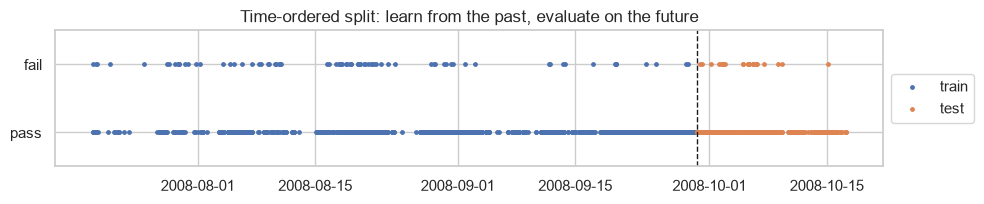

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.scatter(ts_train, y_train, s=6, color="#4C72B0", label="train")
ax.scatter(ts_test, y_test, s=6, color="#DD8452", label="test")
ax.axvline(ts_test.min(), color="k", ls="--", lw=1)
ax.set_yticks([0, 1], ["pass", "fail"]); ax.set_ylim(-0.5, 1.5)
ax.set_title("Time-ordered split: learn from the past, evaluate on the future")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(FIG_DIR / "05_time_split.png", dpi=150)

**해석**: test 불량은 **24개뿐**이다. 평가 지표 하나하나가 불량 몇 개에 크게 흔들린다는 뜻
(불량 1개를 더 잡으면 재현율이 약 4%p 오른다). 결과를 말할 때 이 한계를 함께 언급한다.

train 안에서도 7월(불량 多)과 9월(불량 少)이 섞여 있다. test는 최근 기간이라 **불량률이 낮은 시기**다.

## 2. 테스트 기간에만 나타난 센서 오류값

전처리를 만들다가 발견한 것: 일부 센서가 test 기간에 **학습 기간 범위를 수천 배 벗어난 값**을 가진다.

In [4]:
rows = []
for c in ["sensor_140", "sensor_275", "sensor_004", "sensor_390"]:
    over = X_test[c][X_test[c] > X_train[c].max()]
    rows.append({"sensor": c,
                 "train 범위": f"{X_train[c].min():.3g} ~ {X_train[c].max():.3g}",
                 "test 최대값": f"{X_test[c].max():.5g}",
                 "범위 초과 행 수": len(over),
                 "그 행들의 불량률": f"{y_test.loc[over.index].mean():.0%}" if len(over) else "-"})
pd.DataFrame(rows)

,sensor,train 범위,test 최대값,범위 초과 행 수,그 행들의 불량률
0,sensor_140,0.0319 ~ 3.23,9998.9,4,0%
1,sensor_275,0.0111 ~ 1.54,3332.6,4,0%
2,sensor_004,0.681 ~ 3.89,1114.5,4,0%
3,sensor_390,0.305 ~ 9.66,805.39,1,0%


**해석**: `9998.9`, `1112.2` 같은 값은 실제 측정이라기보다 **센서 오류 코드**(계측 실패 시 9999 등을 기록)로 보인다.
4개 행에 몰려 있고 모두 정상품이다.

- **로지스틱 회귀**는 `값 × 가중치`를 더하므로, 9999 하나가 점수 전체를 지배할 수 있다.
  → **`ClipToTrainRange`**: 각 센서를 train에서 본 [최소, 최대] 범위로 자른다 (범위도 train에서만 학습).
- **LightGBM**은 "값이 X보다 큰가?"만 묻기 때문에, 9999는 그냥 "가장 큰 쪽" 가지로 갈 뿐 문제가 커지지 않는다. → 자르지 않음.

## 3. 로지스틱 회귀용 Pipeline

```
DropHighMissing(50%) → SimpleImputer(median) → VarianceThreshold(0) → ClipToTrainRange → StandardScaler
```

| 단계 | 하는 일 | 이유 |
|---|---|---|
| DropHighMissing | train 결측률 50% 초과 센서 제거 | 절반 이상 추정값으로 채우면 신뢰 불가 |
| SimpleImputer | 남은 결측을 train **중앙값**으로 | 센서값은 치우침·이상치가 있어 평균보다 안전 |
| VarianceThreshold | train에서 값이 하나뿐인 센서 제거 | 정보 0 |
| ClipToTrainRange | train 범위 밖 값 자르기 | 센서 오류값 영향 차단 |
| StandardScaler | 평균 0, 표준편차 1로 | 가중치 크기를 공정하게 비교, L2 규제가 공평하게 작동 |

**순서도 이유가 있다**: 결측을 먼저 채워야 분산·범위 계산이 가능하고, 오류값을 자른 뒤에 표준화해야 평균·표준편차가 오류값에 끌려가지 않는다.

In [5]:
linear = build_linear_preprocessor()
Xtr_lin = linear.fit_transform(X_train, y_train)   # fit: train에서만 학습
Xte_lin = linear.transform(X_test)                 # transform: train에서 배운 값으로 변환만

def n_cols_after(pipe, X, upto):
    out = X
    for name, step in pipe.steps:
        out = step.transform(out)
        if name == upto:
            return out.shape[1]

steps = pd.DataFrame({
    "단계": ["원본", "DropHighMissing", "SimpleImputer", "VarianceThreshold", "ClipToTrainRange", "StandardScaler"],
    "센서 수": [X_train.shape[1]] + [n_cols_after(linear, X_train, n) for n in
                                   ["drop_missing", "impute", "drop_constant", "clip", "scale"]],
})
steps["제거"] = (-steps["센서 수"].diff()).fillna(0).astype(int)
steps

,단계,센서 수,제거
0,원본,590,0
1,DropHighMissing,566,24
2,SimpleImputer,566,0
3,VarianceThreshold,444,122
4,ClipToTrainRange,444,0
5,StandardScaler,444,0


In [6]:
check = pd.DataFrame({
    "train": [Xtr_lin.isna().sum().sum(), Xtr_lin.mean().abs().max(), Xtr_lin.std().mean(), Xtr_lin.abs().max().max()],
    "test":  [Xte_lin.isna().sum().sum(), Xte_lin.mean().abs().mean(), Xte_lin.std().mean(), Xte_lin.abs().max().max()],
}, index=["결측 셀 수", "평균의 절댓값(대표값)", "표준편차 평균", "절댓값 최대"])
check.round(3)

,train,test
결측 셀 수,0.000,0.000
평균의 절댓값(대표값),0.000,0.210
표준편차 평균,1.000,0.873
절댓값 최대,34.257,30.116


**해석**
- 590 → **444개** 센서 (고결측 24개, 상수 122개 제거). EDA에서는 고결측 28개·상수 116개였는데 숫자가 다른 이유:
  이번엔 **train만 보고** 판단했기 때문이다. train에서만 상수인 센서가 더 있고, 전체 기준 50%를 넘던 센서 일부는 train에서는 50% 이하였다.
  → "전처리 기준을 train에서 정한다"는 원칙이 실제로 결과를 바꾼다는 증거.
- train은 정확히 평균 0·표준편차 1. test는 평균·표준편차가 0·1에서 **약간 벗어난다** — 정상이다.
  test를 train 기준으로 변환했으므로, 그 차이가 곧 **기간 간 분포 변화(drift)**다.
- `ClipToTrainRange` 없이 돌리면 test 표준편차 평균이 **약 14.9**까지 튄다(오류값 때문). 지금은 1 근처.

## 4. LightGBM용 Pipeline

```
DropHighMissing(50%) → VarianceThreshold(0)
```

결측 대체·범위 자르기·표준화를 **하지 않는다**.
- LightGBM은 학습 중에 "결측이면 왼쪽/오른쪽 중 어디로 보낼지"를 스스로 정한다 → 결측을 중앙값으로 덮으면 오히려 "결측이었다"는 정보가 사라진다.
- 트리는 값의 **순서**만 사용하므로 단위·스케일이 결과에 영향을 주지 않는다.

In [7]:
tree = build_tree_preprocessor()
Xtr_tree = tree.fit_transform(X_train, y_train)
Xte_tree = tree.transform(X_test)
print(f"LightGBM 입력: train {Xtr_tree.shape}, test {Xte_tree.shape}, 결측 셀(그대로 유지) {Xtr_tree.isna().sum().sum()}")

LightGBM 입력: train (1175, 444), test (392, 444), 결측 셀(그대로 유지) 9921


## 5. 결측 지시자 옵션 (`add_indicator=True`)

EDA에서 "결측 여부가 불량과 연관돼 보이지만 시기와 교란됐을 수 있다"고 봤다. 그래서 **켜고/끄고 둘 다 실험**할 수 있게 옵션으로 만들었다.

- train에서 결측률 5% 이상인 센서에 대해 `<센서>_isna` (0/1) 열을 추가
- **DropHighMissing보다 먼저** 실행 → 값이 버려지는 센서(예: `sensor_085`, train 결측 50% 초과)도 "결측이었다"는 정보는 남는다

In [8]:
lin_ind = build_linear_preprocessor(add_indicator=True)
Xtr_ind = lin_ind.fit_transform(X_train, y_train)
flags = [c for c in Xtr_ind.columns if c.endswith("_isna")]
print(f"지시자 열 {len(flags)}개 추가 → 총 {Xtr_ind.shape[1]}개 피처")
print("예:", flags[:6])

지시자 열 52개 추가 → 총 496개 피처
예: ['sensor_072_isna', 'sensor_073_isna', 'sensor_085_isna', 'sensor_109_isna', 'sensor_110_isna', 'sensor_111_isna']


## 6. 누수 방지는 테스트로 확인

`tests/test_preprocess.py`가 다음을 자동으로 확인한다.
- 시간순 분할에서 train의 모든 행이 test보다 앞선다
- 중앙값·클리핑 범위가 **train 값과 정확히 일치**한다 (전체 데이터 값이 아님)
- test에만 있는 오류값(1000.0)이 잘려 나간다
- 상수·고결측 열이 제거되고, train/test 열 순서가 같다
- 지시자는 값이 버려진 센서에도 남는다

In [9]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True).stdout[-300:])

.....                                                                    [100%]
5 passed in 1.49s



## 요약 → 다음 단계

| 결정 | 근거 |
|---|---|
| 시간순 75/25 분할 | 실제 운영 조건 재현, drift 반영 |
| 기준값은 train에서만 학습 (Pipeline) | 누수 방지 — EDA 수치와 train 기준 수치가 실제로 달랐음 |
| 로지스틱: 대체 + 클리핑 + 표준화 | 선형 모델은 결측·스케일·극단값에 민감 |
| LightGBM: 결측 유지, 스케일 생략 | 트리는 결측을 직접 다루고 순서만 사용 |
| 결측 지시자는 옵션 | 교란 가능성 때문에 on/off 비교로 검증 |

다음(03): 이 두 Pipeline 뒤에 **로지스틱 회귀**와 **LightGBM(class_weight)**를 붙여 PR-AUC·불량 재현율로 비교한다.